# 零、总述

**文本嵌入模型**是强大的 NLP 应用的基石，它们为许多文本生成模型赋能。在本章中，我们将会讨论创建和微调嵌入模型的几种方式，以增加它们的表示和语义能力。

我们从探索嵌入模型是什么开始，之后探讨它们是如何工作的？

# 一、Embedding Models

模型非常难处理非结构化的文本数据，所以，我们可以将文本数据转换为数字的表示，我们称其为 **embedding**。做这种嵌入操作的模型叫做嵌入式模型（Embedding Model）。然而，嵌入向量表示成什么最精确呢？一般情况下，我们可以捕捉文档的语义，也就是那些语义相近的文档应该在其嵌入空间中有着更近的距离或者更高的相似度。但是，文档一开始嵌入到向量空间中是随机分布的，我们就需要训练此模型以让他表现的更优。

有许多训练、微调和引导嵌入模型的方式，但最强大的且最广泛使用的技术是**对比学习（Contrastive Learning）**

# 二、什么是对比学习？

**对比学习**的目标是训练嵌入模型在嵌入的向量空间中让相似文档离得更近，不相似的文档离得更远。训练过程如下图所示：

<center>
<img src="./resources/contrastive_learning.png">
</center>

从**解释的本质**视角，我们可以审视一下对比学习。举个例子：一则故事是这样说的，记者问抢劫犯：“你为什么要抢劫银行？”，他说：“因为银行里面钱多”。虽然说这个答案是正确的，但是这个问题的意图不仅仅是说你为什么要抢劫银行，而是说你为什么要抢劫银行而不是去遵守法律。这就称作**Contrastive explanation**，即：**与 “为什么 P？” 相对的备选项是 “为什么 P 而不是 Q？”**

从不同角度理解问题，或者深入的理解问题所询问的本质，这种思想也可以应用于对比学习，在模型学习文档相似/不相似的时候，它可以更进一步学习为什么这些文档相似/不相似。举个例子：你可以让模型理解一张狗的图像：它有鼻子，尾巴，四条腿。但是有鼻子，尾巴和四条腿的生物不能是只猫么？为了加强模型的这种理解，我们可以问模型“为什么是狗而不是猫？”，那么模型就会对比两个概念，去找它们的差异性。

下图是马和斑马的特征比较：
<center>
<img src="./resources/horse_zebra_contrastive.png">
</center>



# 三、SBERT

`sentence-transformers` 是一个在 NLP 领域内很好的三方库，它解决了 BERT 中实现句子嵌入的问题 —— 计算开销（Computation Overhead）太大了。在 `sentence-transformers` 之前，BERT 中的句子嵌入使用的是一种 Cross-Encoder 的架构。

Cross-Encoder 会让两个句子传递到 Transformer 中，用来预测两个句子的相似程度。它用添加分类头的方式来实现，分类头可以输出相似度分数。然而，当大量的句子进入此架构时，计算量会急剧增加，例如，有 10,000 个句子，那它就需要比较 $n(n-1)/2 = 49,995,000$ 次。另外，Cross-Encoder 不生成嵌入，输出的仅仅是句子之间的相似度分数。

Cross-Encoder 的架构如下图所示：

<center>
<img src="./resources/cross_encoder_architecture.png">
</center>

`sentence-transfomers` 的作者则另辟蹊径，致力于寻找一种计算效率高、且能够生成支持语义相似度比较的 Embedding 的方法。
和 Cross-Encoder 架构不同，`sentence-transformers` 删除掉了分类头，取而代之的是**平均池化（Mean Pooling）**，它用来在最终的输出层上生成嵌入向量。池化层会平均词嵌入向量并且会返回固定维度的向量。

`sentence-transformers` 使用了一个孪生的架构（Siamese Architecture）, 如下图所示。两个等同的 BERT 模型共享了相同的权重和神经网络架构。这些模型的输入是句子，输出是池化后的嵌入向量，模型优化的指标是句子嵌入向量之间的相似度。

<center>
<img src="./resources/sentence_transformers_architecture.png">
</center>


# 四、创建一个嵌入模型

创建嵌入模型有很多种方式，**对比学习（Contrastive Learning）** 是最重要的方式，因为它可以学习有效的语义表示。

那么，使用对比学习创建 Embedding 模型的过程分为三步：

1. 构建对比样本
2. 训练模型
3. 评估模型

## 4.1 构建对比样本

在预训练 Embedding 模型的时候，你经常看到他们使用 NLI（Natural Language Inference, 自然语言推理） 数据集。**NLI** 是这样一项任务：对于给定的前提，判断这个前提是否包含这个假设**(Entailment，包含)**，是否与之冲突**(Contradiction， 冲突)**，或者两者皆不**（Neutral，中立）**。

举个例子：

在前提是："他在电影院看 Coco" 的情况下，假设 “他在家里正在观看 Frozen” 就与它冲突，假设“它在电影院看迪士尼的电影 Coco” 就与之是包含关系。如下图所示

<center>
<img src="./resources/contrastive_samples.png">
<center>

`Entailment` 和 `Contradiction` 都是在描述两个输入的相似程度，正因为这种特性，我们可以使用 NLI 数据集来生成正负样本对。在创建和微调嵌入模型过程中，我们使用的数据源于 **GLUE**（General Language Understanding Evaluation benchmark, 通用语言理解评测基准），GLUE 基准测试包含九种语言的理解任务，用于评估和分析模型性能。

这些任务其中之一是多体裁自然语料推理 (MNLI, Multi-Genre Natural Language Inference) 语料库, 它包含了 392702 条语句对，每一对都被标记为 `Entailment`、`Contradiction`或`Neutral`。由于时间语设备的限制，我们仅使用其中的 50,000 对来训练模型。要注意的是：**数据集越小，训练和微调嵌入模型会变得越不稳定。**

In [ ]:
from datasets import load_dataset

# 从 GLUE 中加载 MNLI 数据集
# 0 - entailment, 1 - neutral, 2 - contradiction

train_dataset = load_dataset(
    "glue", "mnli", split="train"
).select(range(50_000))

train_dataset = train_dataset.remove_columns("idx")

我们看一个例子

In [ ]:
train_dataset[2]

## 4.2 训练嵌入模型

现在我们已经有训练集的数据了，接下来我们来训练嵌入模型。现在让我们从零训练嵌入模型。

那么，我们需要考虑以下几件事

1. 选什么模型作为基础模型呢？
2. 应该使用什么损失函数？
3. 怎么去评估模型的好坏呢？

### 4.2.1 基础模型的选择

训练一个 Embedding 模型，首先需要选择合适的预训练模型作为底座（Backbone），其作用是**将输入文本编码为具有上下文语义信息的嵌入向量（Token 维度），为后续构建句子的向量提供基础**。例如 BERT、RoBERT 和 MPNet 都可以作为 Embeding 模型的底座。

目前，我们可以从两个维度来选择 Embedding 基座：**按模型架构选择** 和 **按预训练模型的来源选择**。除此之外，底座选选择的关键因素还有**目标语言、模型参数规模，最长输入长度和训练与推理成本**等等


#### 4.2.1.1 按模型架构选择

现在语言模型的架构分为以下三种

| 架构           | 代表模型 | 适用场景 |
|--------------|---|---|
| Encoder-only | BERT、RoBERTa、MPNet | 传统文本 Embedding、语义检索 |
| Decoder-only |Qwen、Llama | 基于大语言模型构建 Embedding |
| Encoder-Decoder | T5、BART | 特定文本表示与多任务学习场景 |

因此，对于传统的双编码器 Embedding 模型，优先考虑 Encoder-only 架构的模型，常见选择如下表所示

| 架构          | 代表模型            | 特点            |
|-------------|-----------------|---------------|
| BERT        | BERT-base       | 结构经典，资料丰富     |
| RoBERTa     | RoBERTa-base    | 改进 BERT 预训练方式 |
| MPNet       | MPNet-base      | 结合掩码与排列预测思想   |
| DistillBERT | DistillBERT     | 模型小，训练成本低     |
| ModernBERT  | ModernBERT-base | 较新的编码器架构，支持较长上下文 |

#### 4.2.1.2 按预训练模型的来源选择

目前，我将预训练模型的来源分为以下三种

**1. 通用预训练语言模型（General Pretrained Language Model）**

直接选择已经完成语言预训练的 Transformer，之后再通过对比学习训练 Embedding

代表模型有：
- google-bert/bert-base-uncased
- FacebookAI/roberta-base
- microsoft/mpnet-base
- hfl/chinese-macbert-base

**适合**：从头学习 SBERT、研究不同损失函数、构建自己的句子嵌入模型

**2. 领域预训练语言模型（Domain-Specific Pretrained Language Model）**

选择已经针对某个专业领域进行过预训练的模型，再训练 Embedding

例如：
- BioBERT: 生物医学领域
- SciBERT: 科学文献领域
- ClinicalBERT: 临床文本领域

其优势是：**底座已经学习了一定的专业术语和领域语言特征**

**适合**：专业领域的 Embedding 训练

**3. 已训练好的 Embedding 模型（Pretrained Embedding Model）**

直接选择一个已经通过语义对比学习训练的 Embedding 模型，再用自己的数据进行微调

代表模型：
- BAAI/bge-small-zh-v1.5
- thenlper/gte-small
- sentence-transformers/all-mpnet-base-v2
- intfloat/multilingual-e5-base

这类模型已经具备句子语义表示能力，可以在现有基础上进行领域适配

**适合**：企业 RAG、知识库检索、语义检索等实际项目

由于我们要进行后续的训练和调优，我们使用 `bert-base-uncased` 作为基础的模型（Backbone）

In [ ]:
from sentence_transformers import SentenceTransformer

backbone_model = SentenceTransformer("bert-base-uncased")

### 4.2.2 嵌入模型的损失函数

按照训练目标，可以将常见损失函数划分为以下几类

| **类别**    | **代表损失函数** | **核心目标** |
|-----------|---|---|
| 分类损失      | SoftmaxLoss | 通过分类任务学习语义表示 |
| 相似度回归损失   | CosineSimilarityLoss | 预测句子之间的相似度 |
| 对比损失      | ContrasitiveLoss、OnlineContrastiveLoss | 拉进正样本，推远负样本 |
| 三元组损失     | TripletLoss、BatchHardTripletLoss | 保证正样本比负样本更接近 Anchor |
| 多负样本排序损失  | MultipleNegativesRankingLoss、CachedMultipleNegativesRankingLoss | 从多个候选中识别正确匹配 |
| 相似度排序损失   | CoSENTLoss、AnglEloss | 保持预测的相似度排序与标注一致 |
| 无监督表示学习损失 | ContrastiveTensionLoss、DenoisingAutoEncoderLoss | 从无标签文本学习表示 |
| 蒸馏损失      | MSELoss、MarginMSELoss、DistillKLDivLoss | 将教室模型的知识迁移给学生模型 |
| 结构增强损失 | MatrypshkaLoss、AdaptiveLayerLoss | 支持多维度向量或不同层数的推理 |


下面介绍几个比较重要的损失函数

#### 4.2.2.1 分类损失: SoftmaxLoss

SoftmaxLoss 即我们常说的交叉熵损失，它基于分类的文本。

其公式如下：

$$
\mathcal{L}_{CE} = - \sum_{k=1}^K y_k \log(p_k)
$$

其中：
- $K$: 类别数量，NLI 上通常为 3
- $y$: 真实类别的标签分布
- $p$: 模型预测的类别概率

其适用场景有：

- NLI 自然语言推断训练
- 具有明确类别标签的句子对训练
- 复现原始 SBERT 的训练方法


#### 4.2.2.2 余弦相似度损失：CosineSimilarityLoss

假设现在有两个句子$u$, $v$，余弦相似度的数学公式如下

$$
\text{sim}(u, v) = \frac{u v}{||u||||v||}
$$

最后默认均方误差作为损失函数

$$
\mathcal{L} =\frac{1}{N} \sum_{i=1}^N(\text{sim}(u, v) - y_i)^2
$$

其中：
- $N$: 句子对的数量
- $y_i$: 代表第 $i$ 个句子的人工标注的真实相似度

适用场景有：

- Semantic Textual Similarity(STS) 任务
- 有连续相似度标签的数据集
- 希望模型的相似度分数接近标注值的任务

#### 4.2.2.3 对比损失：ContrastiveLoss

ContrastiveLoss 通过正负样本对训练模型。

其目标是:**减少正样本对的嵌入向量之间的距离，增大负样本对之间的距离，直到达到指定间隔为止**

一种经典的对比损失形式是：

$$
\mathcal{L} = yD^2 + (1 - y) max(0, m-D)^2
$$

其中：

- $y$: 正负样本标签，1 - 正样本，0 - 负样本
- $D$：两个 Embedding 之间的距离
- $m$: Margin，间隔的阈值，即负样本对之间起码距离 $m$

那么，当 $y = 1$ 时，损失为：

$$
\mathcal{L} = D^2
$$

即：最小化 Embedding 之间的距离

当 $y = 0$ 时，损失为：

$$
\mathcal{L} = max(0, m-D)^2
$$

即：让负样本对的 Embedding 之间的距离 $D \le m$

此损失的使用场景可以是：句子去重、语义相似度分类以及具有明确正负标签的文本匹配任务。

#### 4.2.2.4 三元组损失

TripletLoss 使用三个输入：

- **Anchor**：基准文本
- **Positive**：与 Anchor 语义相近的文本
- **Negative**: 与 Anchor 语义不同的文本

例如，如果 Anchor 是“如何修改用户密码？”，则 Positive 是 “忘记密码后应该怎样重置？”，Negative 是 “企业应该如何申请发票？”

TripletLoss 与 ContrastiveLoss 不同，它会同时比较正负样本与 Anchor 之间的距离，其公式如下：

$$
\mathcal{L} = max(0, D(A, P) - D(A, N) + m)
$$

其中：

- $D(A, P)$ 表示 Anchor 与 Positive Sample 的距离
- $D(A, N)$ 表示 Anchor 与 Negative Sample 的距离
- $m$ 表示正负样本必须相距一定的间隔

则训练目标是：

$$
D(A, P) + m \le D(A, N)
$$

<center>
<img src="./resources/1.svg">
</center>

TripletLoss 还有多个变体

| 损失函数                           | 特点                                   |
|--------------------------------|--------------------------------------|
| BatchAllTripletLoss            | 使用批次内所有有效的三元组                        |
| BatchHardTripletLoss           | 选择批次内距离 Anchor 最远的正样本和最近的负样本         |
| BatchSemiHardTripletLoss       | 选择距离 Anchor 比正样本远、但未满足 Margin 要求的负样本 |
| BatchHardSoftMarginTripletLoss | 选择距离 Anchor 最远的正样本和最近的负样本，使用 Soft Margin，无需手动设置固定 Margin |


<center>
<img src="./resources/triplet_hard_vs_semihard.png">
</center>

<center>
<img src="./resources/triplet_soft_margin.png">
</center>
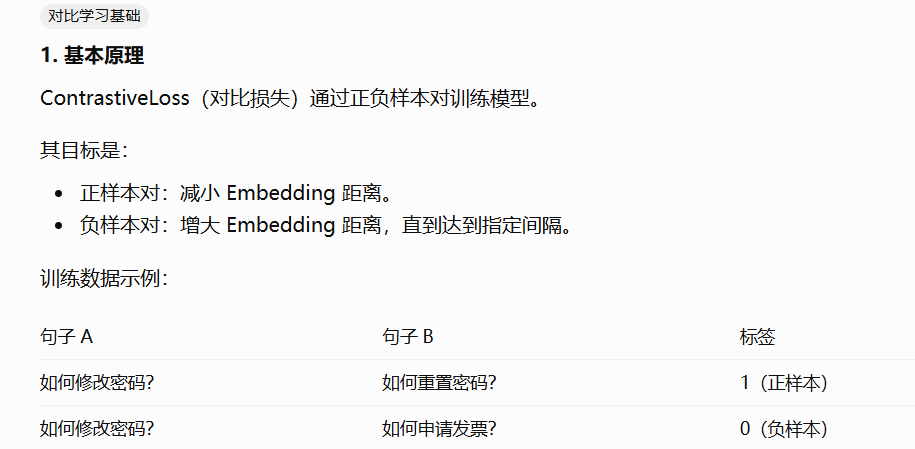

#### 4.2.2.5 多负样本排序损失（MNRL）

MultipleNegativeRankingLoss(MNRL) 适合 SBERT、Bi-Encoder 和 RAG 检索模型

它的核心思想是：**让 Anchor 与对应正样本的相似度高于同一个批次中所有负样本的相似度**，这种方法称为 **In-Batch Negatives(批次内负样本)**

假设我们正在训练一个用于 RAG 检索的 Embedding 模型

训练数据有三组正样本对：

| Anchor（查询）|	Positive（相关文档）|
|---|--|
| A₁：什么是机器学习？|	P₁：机器学习是一种人工智能技术|
| A₂：Python 如何排序？|	P₂：Python 可以使用 sorted() 排序|
| A₃：什么是光合作用？|	P₃：植物利用光能合成有机物的过程|

那么我们会构建这样一组数据

- Anchor: 什么是机器学习？
- Positive: 机器学习是一种人工智能技术
- Negative1: Python 可以使用 sorted() 排序
- Negative2: 植物利用光能合成有机物的过程

构造过程如下图所示

<center>
<img src="./resources/in_batch_negative.svg">
</center>

那么，对于一个大小为 $N$ 的 Batch:

- 每个 Anchor 都拥有一个 Positive
- 默认情况下，其他 $N - 1$ 个 Positive 都被当作这个 Anchor 的负样本

所以，一个批次内会形成 $N(N-1)$ 个有方向的 Anchor-Negative 对比关系

<span style="color: red">**这就是它叫做 Multiple Negative(多负样本)的原因**</span>


再来说，<span style="color: red">**排序损失**</span>，**因为它优化的不是两个句子之间的相似度，而是让正样本在多个候选样本中获得更高的相似度排名。**

MNRL 的损失函数定义为

$$
\mathcal{L} = - \frac{1}{N} \sum_{i=1}^N \log \frac{\exp(s(a_i, p_i))}{\sum_{j=1}^N \exp(s(a_i, p_j))}
$$

其中：

- $N$ 代表批次的大小
- $a_i$ 代表第 $i$ 个 Anchor 的 Embedding 向量
- $p_i$ 代表与 Anchor $a_i$ 正确匹配的正样本的嵌入向量
- $p_j$ 代表 Batch 中的第 $j$ 个正样本的嵌入向量
- $s(a_i, p_j)$ 代表 Anchor 和候选 Positive 的相似度


那么，第 $i$ 个 Anchor 的损失就可以表示为：
$$
\mathcal{L}_i = - \log \frac{\exp(s(a_i, p_i))}{\sum_{j=1}^N \exp(s(a_i, p_j))}
$$

我们将分子、分母同时除以 $e^s(a_i, p_i)$，得到：

$$
\mathcal{L}_i = \log \left(1 + \sum_{j \ne i} \large e^{s(a_i, p_j) - s(a_i, p_i)} \right)
$$

可以看到，**单个 Anchor 的损失完全依赖于正负样本相似度的差值**

$s(a_i, p_j)$ 代表 Negative 的相似度，$s(a_i, p_i)$ 代表 Positive 的相似度，如果负样本的相似度更高，则损失越大，反之，损失越小。

所以，**排序** 的意义是让所有的正样本与 Anchor 之间的相似度都大于负样本与 Anchor 之间的相似度， 即：
$$
s(a_i, p_i) > s(a_i, p_j), j \ne i
$$

这也是 MNRL 优化的目标

#### 4.2.2.6 相似度排序损失

相似度排序损失的核心思想是：**不一定要求模型预测出精确的相似度数值，而是要求模型预测的相似度能够保持正确的相对排序**

**相似度排序损失**的基本原理如下：

假设一个 Bacth 中包含 $N$ 个句子对，每个句子对都有一个真实的相似度标签：

$$
\mathcal{D} = \{(a_i, b_i, y_i)\}_{i=1}^N
$$

其中：

- $a_i, b_i$ 代表第 $i$ 个句子对中的两个句子
- $y_i$ 代表人工标注的真实相似度

那么，我们计算经过 Embedding 模型训练的句子对的相似度为：

$$
s_i = cos(f_{\theta}(a_i), f_{\theta}(b_i))
$$

其中：

- $f_{\theta}$ 表示待训练的 Embedding 模型
- $s_i$: 代表模型预测的相似度

我们希望，**如果真实标签满足 $y_i > y_j$，则相对应的 $s_i > s_j$ 也应该成立**

**CoSENTLoss** 和 **AnglELoss** 都属于相似度排序损失，主要用于有监督的 Embedding 模型训练，尤其适用于 STS（Semantic Textual Similarity, 语义文本相似度）任务。

1. CoSENTLoss

CoSENTLoss 的全称为 Cosine SENTence Loss, 其损失公式为：

$$
L = \log \left(1 + \sum_{y_i > y_j} e^{\lambda (s_j - s_i)} \right)
$$

其中：

- $i, j$ 代表两个不同句子对的索引
- $y_i, y_j$ 代表真实相似度标签
- $s_i, s_j$ 代表预测的相似度
- $\sum_{y_i > y_j}$ 表示筛选的句子对满足 $y_i > y_j$
- $\lambda$ 代表缩放系数，控制排序损失的敏感程度

**注意，指数上的算式是 $s_j - s_i$, 而不是 $s_i - s_j$**，它保证了损失越小，效果越好的特性。

2. AnglELoss

AnglELoss 的全称为 Angle Optimized Loss, 它是对 CoSENTLoss 的一种改进。CoSENTLoss 仍依赖于余弦相似度函数，但余弦相似度存在一个问题：**Saturation Zone(饱和区域)**，这意味着余弦相似度对于临近波峰或波谷的区域内的角度变化不够敏感。

例如：夹角从 0° 度变化到 5° 度时，相似度仅变化约 0.0038，而从 85° 变化到 90° 时，相似度变化约 0.0872, 同样是 5 度的角度变化，相似度的变化程度却有很大差别

饱和区域如下图所示

<center>
<img src="./resources/saturation_zone.svg" style="width: 67%; height: auto;">
</center>

所以，为了缓解这个问题，AnglELoss 提出在**复数空间**内优化角度差。它是将实数 Embedding 向量重新解释为复数向量，并利用复数空间中的实部和虚部构造角度相关的优化信号。其来源于欧拉公式

$$
{
\color{orange}
e^{i \theta} = cos(\theta) + i sin(\theta)
}
$$

对于两个 Embedding 向量
$$
\mathbf{u} = [a;b]
$$

$$
\mathbf{v} = [c;d]
$$

其中，$a,b$ 和 $c,d$ 是分别将 $\mathbf{u}$ 和 $\mathbf{v}$ <span style="color: red">拆分成一半维度的 Embedding 向量</span>，例如：$u$ 为 768 维，则 $a,b$ 分别为 384 维。

接下来，我们令：
$$
z = a + bi
$$

$$
w = c + di
$$

我们做除法

$$
\begin{aligned}
\frac{z}{w}
&=\frac{a+bi}{c+di}\\[4pt]
&=\frac{(a+bi)(c-di)}
{(c+di)(c-di)}\\[4pt]
&=\frac{(ac+bd)+(bc-ad)i}
{c^2+d^2}
\end{aligned}
$$

将其归一化后：
$$
\boxed{
\frac{z}{w}\cdot\frac{r_w}{r_z} =
\frac{(ac+bd)+(bc-ad)i}
{\sqrt{(a^2+b^2)(c^2+d^2)}}
}
$$

那么,对于复数 $z$：
$$
\begin{cases}
a=r_z\cos\alpha\\
b=r_z\sin\alpha
\end{cases}
$$

对于复数 $w$：
$$
\begin{cases}
c=r_w\cos\beta\\
d=r_w\sin\beta
\end{cases}
$$

则

$$
\begin{aligned}
ac+bd
&=r_z\cos\alpha\cdot r_w\cos\beta\\
&\quad+r_z\sin\alpha\cdot r_w\sin\beta\\[6pt]
&=r_zr_w(\cos\alpha\cos\beta
+\sin\alpha\sin\beta)
\end{aligned}
$$

$$
\begin{aligned}
bc-ad
&=r_z\sin\alpha\cdot r_w\cos\beta\\
&\quad-r_z\cos\alpha\cdot r_w\sin\beta\\[6pt]
&=r_zr_w(\sin\alpha\cos\beta
-\cos\alpha\sin\beta)
\end{aligned}
$$

则：
$$
\boxed{
\frac{z}{w}\cdot\frac{r_w}{r_z}
=\cos(\alpha-\beta)+i\sin(\alpha-\beta)
}
$$

由于 $z$ 和 $w$ 的相位差是 $\Delta \theta = \alpha - \beta$，那么

$$
\boxed{
\frac{z}{w}\cdot\frac{r_w}{r_z}
=
\underbrace{\cos\Delta\theta}_{\text{实部}}
+
i\underbrace{\sin\Delta\theta}_{\text{虚部系数}}
}
$$

根据欧拉公式，我们可以进一步简化为：

$$
\boxed{
\frac{z}{w}\cdot\frac{r_w}{r_z}
=e^{i\Delta\theta}
}
$$

接下来，我们定义 $q$ 为：

$$
q = \frac{z}{w}\cdot\frac{r_w}{r_z}
=
\cos\Delta\theta
+
i\sin\Delta\theta
$$

那么，Angle Similarity 就定义为：

$$
\color{red}
s_{angle} = \lvert Re(q) + Im(q) \rvert = |\cos\Delta\theta + \sin\Delta\theta|
$$

<span style="color: red">**也就是说，Angle Similarity 携带了两个 Embedding 之间的角度信息**</span>

那我们基于这个相似度来定义损失函数(其实与 CoSENTLoss 的损失函数形式一样)：

$$
\color{orange}
\boxed{
L=\log\left(1+\sum_{y_i>y_j}e^{\lambda(s_j^{angle}-s_i^{angle})}\right)
}
$$



下面来讲一个数学细节：**复数的实数表示**

<span style="color: orange">由于复数不像实数一样具有自然的大小排序关系，因此在机器学习中，如果需要进行相似度排序、计算损失函数等操作，通常需要将复数映射为一个实数</span>

$$
f: \mathbb{C} \rightarrow \mathbb{R}
$$

这种映射有多种方式，不同的方式保留的数学信息也不同

对于复数
$$
z = a + bi
$$

其映射方式如下表所示(例如 $z = 3 + 4i$)：

<center>

| 映射方式 | 英文名称 | 数学公式 | 计算结果 |
|---|---|---|---:|
| 实部 | Real Part | $a$ | 3 |
| 虚部 | Imaginary Part | $b$ | 4 |
| 模长 | Modulus | $\sqrt{a^2+b^2}$ | 5 |
| 模长平方 | Squared Magnitude | $a^2+b^2$ | 25 |
| 相位角 | Argument | $\operatorname{atan2}(b,a)$ | 0.9273 rad |
| 线性组合 | Linear Combination | $w_1a+w_2b$ | 取决于权重 |
| 绝对值聚合 | Absolute Sum | $\lvert a+b\rvert$ | 7 |
</center>

<span style="color: red">**Angle Similarity 使用的就是绝对值的聚合的方式**</span>

另外，再介绍一下相位角函数 $\text{atan2}$

`atan2` (Two-argument Arctangent) 是一个接受两个参数的正切函数，用于计算二维平面上某个向量与 X 轴正方向之间的**有符号夹角**。

对于复数：
$$
z = a + bi
$$
来说。其相位角可以表示为：
$$
\theta = arg(z) = \text{atan2}(b, a)
$$

其中：$\theta \in [-\pi, \pi]$

如下图所示：
<center>
<img src="./resources/complex.svg" style="width: 60%; height: auto;">
</center>


atan2 的数学定义如下

$$
\boxed{
\operatorname{atan2}(b,a)=
\begin{cases}
\arctan\left(\frac{b}{a}\right),
& a>0\\[6pt]
\arctan\left(\frac{b}{a}\right)+\pi,
& a<0,\ b\geq0\\[6pt]
\arctan\left(\frac{b}{a}\right)-\pi,
& a<0,\ b<0\\[6pt]
\frac{\pi}{2},
& a=0,\ b>0\\[6pt]
-\frac{\pi}{2},
& a=0,\ b<0\\[6pt]
\text{未定义},
& a=0,\ b=0
\end{cases}
}
$$

#### 4.2.2.7 无监督表示学习损失

无监督表示学习的主要特点是：**不需要人工标注文本之间的相似度，也不需要提前准备正负样本对。只需要收集大量的原始文本**。

其损失函数主要有 **ContrastiveTensionLoss** 和 **DenoisingAutoEncoderLoss**

1. **ContrastiveTensionLoss**: 对比张力损失

Contrastive Tension(CT) 是一种无监督对比学习方法，通过自动构造正负样本来训练 Embedding 模型，它的构造规则非常简单：*正样本就是两个完全相同的句子，负样本是两个不同的句子*

最后，使用正负样本的二元交叉熵作为损失函数来优化 Embedding 模型

2. **DenoisingAutoEncoderLoss**: 去噪自编码器损失

该损失函数主要用于 TSDAE（Transformer-based Sequential Denoising Auto-Encoder）模型的训练。

其核心思想是：**通过移除部分词的方式给输入的句子添加噪声，然后要求模型通过这个“损坏”句子的 Embedding 恢复原始句子。** 句子的 Embedding 向量构建月精确，重构的句子也越精确。常见的噪声添加的方式包括随机删除 Token、随机遮盖 Token、打乱顺序等，TSDAE 使用的是随机删除的方式。

其处理过程如下图所示：
<center>
<img src="./resources/TSDAE_procedure.png" style="zoom: 60%">
</center>

让我们来做一下数学抽象

假设输入的句子
$$
x = (x_1, x_2, ..., x_T)
$$

那么添加噪声之后得到
$$
\tilde{x} = \text{Noise}(x)
$$

通过 Encoder 得到句子向量：
$$
\mathbf{z} = f_{\theta}(\tilde{x})
$$

其中，**$\theta$ 代表 Encoder 的权重**，之后，Decoder 根据句子向量，自回归地预测原始文本：
$$
P_{\phi}(x | \mathbf{z}) = \Pi^T_{t = 1} P_{\phi}(x_t | x_{<t} \mathbf{z})
$$

其中，**$\phi$ 代表 Decoder 的权重**，那么，我们既然要最大化上述的概率，就要**最小化其负对数似然损失**

$$
\boxed{
L_{\mathrm{DAE}}
=-\sum_{t=1}^{T}
\log P_\phi(x_t\mid x_{<t},\mathbf z)
}
$$


#### 4.2.2.8 知识蒸馏损失

知识蒸馏（Knowledge Distillation）是指将一个模型学习到的知识迁移给另一个模型。通常，提供知识的模型称为 Teacher Model, 学习知识的模型称为 Student Model。

在 Embedding 模型训练中，知识蒸馏主要有三个层次：<span style="color: red">**向量表示，分数差值和概率分布**</span>

如下图所示：
<center>
<img src="./resources/knowledge_distill.svg" style="width: 70%; height: auto;">
</center>

这三个层次各自使用不同的损失函数来优化

1. **向量表示**

这个属于*向量级蒸馏（Embedding-Level Distillation）*, 直接让学生模型生成的 Embedding 接近教师模型生成的 Embedding, 它要求学生向量和教师向量能够**逐元素对齐**，这种“逐元素”的方式非常适合用均方误差损失来优化

假设教师模型输出向量：
$$
\mathbf{t} = f_{teacher}(x)
$$

学生模型输出向量：
$$
\mathbf{s} = f_{teacher}(x)
$$

则单个样本的 MSE Loss 为：
$$
L_{MSE} = \frac{1}{d} \sum_{j=1}^d (s_j - t_j)^2
$$

对于整个 Batch:
$$
\color{red}
L_{MSE} = \frac{1}{Nd} \sum_{i=1}^N \sum_{j=1}^d (s_{ij} - t_{ij})^2
$$

其中：

- $N$ 代表 Batch 中的样本数量
- $d$ 代表 Embedding 的维度
- $s_{ij}$ 和 $t_{ij}$ 分别代表学生模型输出的第 $i$ 个向量的第 $j$ 维元素



2. 分数差值

这属于*分数级蒸馏（Score-Level Distillation）*，他不要求学生模型生成与教师模型完全相同的向量，而是要求**学生模型学习教师模型对不同文档的相对相关性判断**，其对应的损失为 **MarginMSELoss(间隔均方误差损失)**

假设有一个三元组：*Query、Positive 和 Negative*

首先计算教师模型的 Margin：
$$
m_T=s_T(q,p)-s_T(q,n)
$$

其中：

- $q$ 代表 *Query* 向量的嵌入
- $p$ 代表 *positive* 向量的嵌入
- $n$ 代表 *negative* 向量的嵌入

然后计算学生模型的 Margin：
$$
m_S=s_S(q,p)-s_S(q,n)
$$

最终计算两个 Margin 的均方误差：
$$
\color{red}
\boxed{
L_{\mathrm{MarginMSE}}
=\frac{1}{N}\sum_{i=1}^{N}
(m_S^{(i)}-m_T^{(i)})^2
}
$$

其中：$N$ 代表批次大小

3. **概率分布级**

此层级对应的损失为 **DistillKLDivLoss(KL 散度蒸馏损失)**。其目标就是让学生模型的概率分布尽可能接近教师模型。

其由 KL 散度（Kullback-Leibler Divergence）实现，也称为相对熵, 它用于**衡量两个概率分布之间的差异**。

对于，同一个 $Query$，有 $K$ 个候选文档

下面公式中的

- $q$ 代表 *Query* 的嵌入向量
- $d_i$ 和 $d_j$ 分别代表第 $i$ 和 $j$ 个候选文档的嵌入向量

首先计算教师模型的概率分布：
$$
P_T(i)=
\frac{\exp(s_T(q,d_i)/\tau)}
{\sum_{j=1}^{K}\exp(s_T(q,d_j)/\tau)}
$$

然后计算学生模型的概率分布：
$$
P_S(i)=
\frac{\exp(s_S(q,d_i)/\tau)}
{\sum_{j=1}^{K}\exp(s_S(q,d_j)/\tau)}
$$

最后计算 KL 散度：
$$
\boxed{
D_{\mathrm{KL}}(P_T\parallel P_S)
=
\sum_{i=1}^{K}
P_T(i)\log\frac{P_T(i)}{P_S(i)}
}
$$

经典的共享温度蒸馏形式还会乘以温度的平方：
$$
\color{red}
\boxed{
L_{\mathrm{DistillKLDiv}}
=\tau^2 D_{\mathrm{KL}}(P_T\parallel P_S)
}
$$

最后说一下，这几个公式中的 $\tau$，它表示温度，是一个超参数，用来控制平滑程度

#### 4.2.2.9 结构增强损失

结构增强损失的主要目的并不是重新定义语义相似度，更严格说的它们属于 **损失修饰器（Loss Modifier）**, 通常需要与其他基础损失函数结合使用，主要有 **MatryoshkaLoss** 和 **AdaptiveLayerLoss** 损失。

这两个损失函数实际上是从两个不同的方向压缩 Embedding 模型，如下图所示

<center>
<img src="./resources/structure_augment_loss.svg" style="width: 67%; height: auto;">
</center>

1. **MatryoshkaLoss(套娃损失)**

MatryoshkaLoss 在训练过程中同时优化多个向量维度，所以，我们可以将一个 768 维的向量截取为 $512, 256, 128, 64, ...$ 等等维度的向量，之后我们计算最终的套娃损失（在基础损失为 MultipleNegativesRankingLoss 时）：

$$
\begin{aligned}
L_{\mathrm{Matryoshka}}={}&
w_{768}L_{\mathrm{MNRL}}^{768}\\
&+w_{512}L_{\mathrm{MNRL}}^{512}\\
&+w_{256}L_{\mathrm{MNRL}}^{256}\\
&+w_{128}L_{\mathrm{MNRL}}^{128}\\
&+w_{64}L_{\mathrm{MNRL}}^{64}
\end{aligned}
$$

我们将其抽象，假设基础损失函数为 $L_{base}$，之后选择需要优化的维度集合

$$
\mathcal{D} = \{64, 128, 256, 512, 768\}
$$

则 MatryoshkaLoss 可以表示为

$$
\color{red}
\boxed{
L_{Matryoshka} = \sum_{d \in \mathcal{D}} w_d L_{base}(\mathbf{z}_{:d})
}
$$

其中：

- $w_d$ 表示不同维度损失的权重
- $\mathbf{z}$ 代表一个嵌入向量
- $\mathbf{z}_{:d}$ 代表对嵌入向量取前 $d$ 维

2. **AdaptiveLayerLoss**：自适应层的损失

传统的 Embedding 模型通常使用 Transformer 最后一层的隐藏状态进行池化，从而得到句子向量。**AdaptiveLayerLoss 的目的就是让模型的中间层也可以输出具有良好的语义表达能力的 Embedding**。

假设模型共有 $L$ 层，第 $l$ 层的池化输出为：

$$
\mathbf{z}^{(l)} = \text{Pooling}(\mathbf{H}^{(l)})
$$

首先，对最后一层计算基础损失
$$
L_{last} = L_{base}(\mathbf{z}^{(L)})
$$

其次，对选中的中间层计算基础损失：
$$
L_{prior} = \sum_{l \in \mathcal{S}} w_l L_{base}(\mathbf{z}^{(l)})
$$

其中：$\mathcal{S}$ 代表选中的层数集合，例如选中第 $\{6, 9, 15, 24, ...\}$ 层

除此之外，还可以将最后一层作为教师模型，中间层作为学生模型，引入 KL 散度进行模型内部的知识蒸馏：

$$
L_{KD} = \sum_{l \in \mathcal{S}} D_{KL}(P^{(L)} || P^{(l)})
$$

因此，AdaptiveLayerLoss 的核心目标可以概括为：
$$
\color{red}
\boxed{
L_{Adaptive} = \alpha L_{last} + \beta L_{prior} + \gamma L_{KD}
}
$$

### 4.2.3 嵌入模型的评估

Embedding 模型的评估分为**评估指标（Metric）** 和 **评估基准(Benchmark)**，它们是两个不同的概念：**指标（Metric）** 定义如何计算模型的性能得分，而**评估基准（Benchmark）** 不仅包含一系列评估指标，还包含标准化的数据集、评估任务和评估流程等等。

在这里，我们只介绍几种**评估基准**，因为 Embedding 模型的评估指标通常需要根据下游任务来选择

目前比较有代表性的评估基准包括

| 评估基准          | 英文全称                                                               | 主要用途         |
|---------------|--------------------------------------------------------------------|--------------|
| STS Benchmark | Semantic Textual Similarity Benchmark                              | 语义文本相似度      |
| GLUE          | General Language Understanding Evaluation                          | 通用自然语言理解     |
| SICK          | Sentences Involving Compositional Knowledge                        | 语义相关性，自然语言推理 |
| BEIR          | Benchmarking Information Retrieval                                 | 信息检索与零样本泛化能力 |
| MTEB          | Massive Text Embedding Benchmark                                   | 综合文本嵌入能力     |
| C-MTEB        | Chinese Massive Text Embedding Benchmark                           | 中文文本嵌入能力     |
| MMTEB         | Multilingual Massive Text Embedding Benchmark                      | 多语言文本嵌入能力    |
| MIRACL        | Multilingual Information Retrieval Across a Continuum of Languages | 多语言信息检索      |





下面只针对 MTEB 做详细讲解

**MTEB（Massive Text Embedding Benchmark, 大规模文本嵌入基准测试）** 是一个专门用于评估文本嵌入模型综合能力的评估基准。MTEB 的核心思想是：**不存在一个单一的评估任务，能够全面衡量 Embedding 模型的性能**

例如，一个 Embedding 模型可能有以下特点：

- 在语义文本相似度任务中表现优秀，但在信息检索任务中表现较差
- 能够很好地区分不同类别的文本，但无法有效匹配跨语言文本
- 在短文本任务中表现优秀，但在长文档检索任务中表现较差

因此，MTEB 将多种类型的文本嵌入任务、数据集、评估指标和评估流程整合到一个统一的框架中，从多个维度评估 Embedding 模型。它首次提出时间在 2022 年 10 月，最原始的任务有 8 类，数据集有 58 个，覆盖语言有 112 种，如下图所示

<center>
<img src="./resources/MTEB.png" style="zoom: 60%">
<center>

下面讲解 MTEB 的八类评估任务

1. Bitext Mining: 双语文本挖掘

它主要用于从两组不同语言的文本中，寻找互为翻译或语义等价的文本对，其主要目的是**评估模型的跨语言语义对齐能力**

2. Classification：文本分类

文本分类用于评估 Embedding 模型生成的向量是否有良好的类别区分能力，这里并不是让 Embedding 模型输出文本类别，而是在生成的向量之上训练一个简单的分类器

代表性数据集如下：

| 数据集	 |评估内容 |
| Banking77 |	77 种银行业务意图分类 |
| AmazonReviews |	商品评论分类 |
| AmazonPolarity |	商品评论正负情感分类 |
| IMDB |	电影评论情感分类 |
| Emotion |	情绪分类 |
| MassiveIntent |	用户意图分类 |
| MassiveScenario |	用户场景分类 |
| MTOPIntent |	多语言意图分类 |
| MTOPDomain |	多语言领域分类 |

3. Clustering: 文本聚类

文本聚类用于评估模型能否将语义相似的文本映射到向量空间中相近的位置，从而形成具有语义意义的簇。原始的 MTEB 使用的是小批次的 K-Means 进行聚类，簇的数量 K 设置为数据集中不同类别的数量。

代表性数据集如下：

| 数据集 |	评估内容 |
|---|---|
| ArxivClustering |	学术论文主题聚类 |
| BiorxivClustering |	生物学论文主题聚类 |
| MedrxivClustering |	医学论文主题聚类 |
| RedditClustering |	社区帖子主题聚类 |
| StackExchangeClustering |	社区问答主题聚类 |
| TwentyNewsgroups |	新闻主题聚类 |

4. Pair Classification: 文本对分类

文本对分类用于**判断两个文本之间是否存在某种指定的关系，例如是否重复，是否互为释义等等**，与普通 Classification 不同，它的输入不是单个文本，而是两个文本。

5. Reranking: 重排序

重排序是指给定一个 Query 和一组候选文档，模型需要根据相关性对候选文档重新排序。

代表性数据集如下：

| 数据集	                       | 评估内容           |
|----------------------------|----------------|
| AskUbuntuDupQuestions      | 	Ubuntu 相似问题排序 |
| StackOverflowDupQuestions	 | 编程相似问题排序       |
| SciDocsRR                  | 	学术论文相关性排序     |
| MindSmallReranking         | 	新闻推荐排序        |

6. Retrieval：信息检索

信息检索用于评估模型从大量文档中寻找相关文档的能力，这是 RAG、向量数据库、语义搜索等应用**最重要**的评估之一。

它的数据集由三部分组成：**Queries、Corpus（语料） 和 QRels(相关性标注)**

代表数据集如下：

| 数据集	 |领域	|评估内容 |
|---|---|---|
| MS MARCO	 |网页搜索	|文本段落检索 |
| Natural Questions	 |开放域问答	|答案文档检索 |
| HotpotQA	 |多跳问答|	多文档证据检索 |
| SciFact	 |科学|	科学论断证据检索 |
| SciDocs	 |学术|	学术文献检索 |
| FiQA2018	 |金融|	金融问答检索 |
| TREC-COVID	 |医学|	医学论文检索 |
| NFCorpus	 |医学|	医疗信息检索 |
| FEVER |	事实验证|	事实验证证据检索 |
| Quora	 |社区问答|	相似问题检索 |
| ArguAna	 |观点论证|	反方论点检索 |
| DBPedia	 |知识库|	实体检索 |

7. STS: 语义文本相似度

STS（Semantic Textual Similarity）用于评估 Embedding 模型能否正确衡量两个文本之间的语义相似程度

代表数据集如下：

| 数据集 |	评估内容 |
|---|---|
| STSBenchmark |	通用语义相似度 |
| SICK-R |	句子语义相关性 |
| BIOSSES |	生物医学文本相似度 |
| STS12～STS16 |	多领域文本相似度 |
| STS17 |	多语言及跨语言语义相似度 |
| STS22 |	多语言新闻文本相似度 |

8. Summarization: 摘要质量评估

这里要注意：<span style="color: red">这里的 Summarization 并不是要求 Embedding 模型生成摘要，而是利用 Embedding 模型评估其他模型生成的摘要是否具有较好的语义质量</span>

例如，
假设人工参考摘要为：

> Transformer 使用注意力机制建模序列之间的依赖关系。

存在以下三种机器生成摘要：

- Transformer 通过注意力机制捕获序列依赖关系。
- Transformer 是一种用于处理文本的模型。
- Transformer 使用卷积代替注意力机制。

显然，第一种要比后两种好得多

# 五、微调嵌入模型

## 5.1 有监督

## 5.2 增强的 SBERT

# 六、无监督学习

## 6.1 基于 Transformer 的序列去噪自编码器

## 6.2 对于 Domain Adaption 使用 TSDAE